Global search...
Refining with local search...
Optimization success: True
MLE beta  = 0.09113927
MLE gamma = 0.69586085
Log-likelihood at MLE = 46.605446


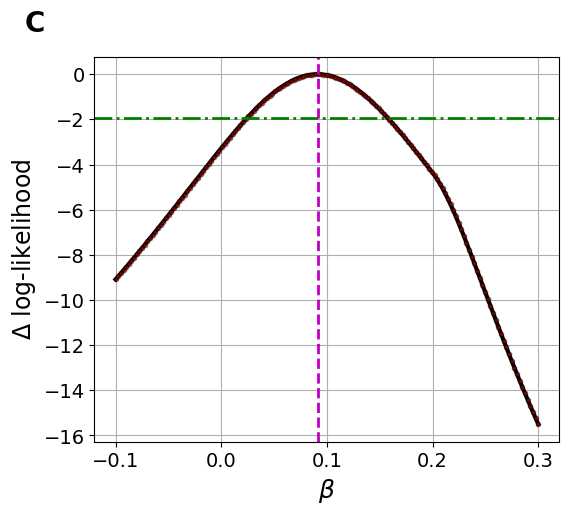

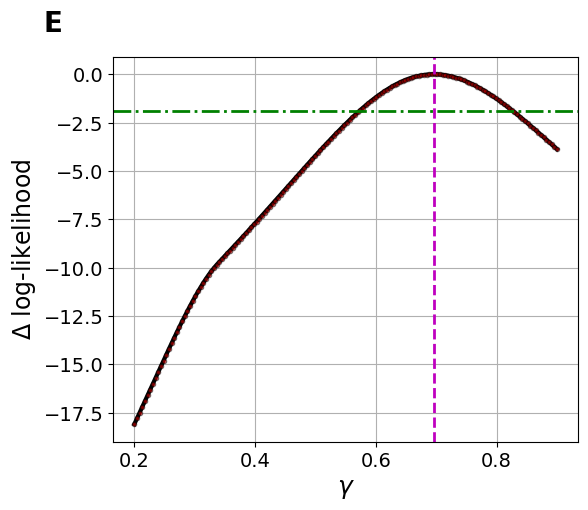

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize, differential_evolution
from scipy.stats import chi2

# =================================
# Experimental data
# =================================
t_obs = np.array([0, 1, 2, 3, 4], float)

# shape: (n_curves, n_time)
y_obs = np.array([
    [0.521, 0.447058824, 0.3375,      0.294117647, 0.216923077],
    [0.363, 0.31,        0.204705882, 0.171052632, 0.12],
    [0.178, 0.145945946, 0.086666667, 0.075,       0.054545455],
], dtype=float)

# initial condition per curve (fixed)
y0_list = np.array([0.521, 0.363, 0.178], dtype=float)

n_curves, n_t = y_obs.shape
N = y_obs.size

# Fixed constants
alpha = 0.3798
delta = 0.4467

# =================================
# ODE RHS (parameters x = [beta, gamma])
# =================================
def ode_rhs(t, y, x):
    beta, gamma = x
    yl = y[0]
    F_l = alpha * yl + beta * (1 - yl)
    F_f = gamma * yl + delta * (1 - yl)
    dydt = (F_l - F_f) * yl * (1 - yl)
    return [dydt]

def solve_one_curve(t_obs, x, y0):
    y0 = float(np.clip(y0, 1e-9, 1 - 1e-9))
    sol = solve_ivp(
        fun=lambda t, y: ode_rhs(t, y, x),
        t_span=(t_obs[0], t_obs[-1]),
        y0=[y0],
        t_eval=t_obs,
        method="LSODA",
        rtol=1e-7,
        atol=1e-9
    )
    if (not sol.success) or (sol.y is None) or np.any(~np.isfinite(sol.y)):
        return np.full_like(t_obs, np.nan, dtype=float)
    return sol.y[0]

def solve_model_all_curves(t_obs, x, y0_list):
    Y = np.zeros((len(y0_list), len(t_obs)), dtype=float)
    for i, y0 in enumerate(y0_list):
        Y[i, :] = solve_one_curve(t_obs, x, y0)
    return Y

# =================================
# Log-likelihood (Gaussian; sigma^2 profiled out)
# NOTE: Do NOT hard-reject beta<0; MATLAB solution needs it.
# =================================
def loglikelihood(x):
    x = np.asarray(x, dtype=float)
    if np.any(~np.isfinite(x)):
        return -np.inf

    y_pred = solve_model_all_curves(t_obs, x, y0_list)
    if np.any(~np.isfinite(y_pred)):
        return -np.inf

    resid = (y_obs - y_pred).reshape(-1)  # length 15
    sigma2 = np.mean(resid**2)
    if sigma2 <= 0 or not np.isfinite(sigma2):
        return -np.inf

    ll = -0.5 * (np.sum(resid**2) / sigma2 + N * np.log(2 * np.pi * sigma2))
    return ll

def neg_ll(x):
    ll = loglikelihood(x)
    return 1e30 if not np.isfinite(ll) else -ll

# =================================
# Optimization (MLE) over [beta, gamma]
# FIXED bounds: allow negative beta like MATLAB
# =================================
bounds = [(-0.1, 0.3), (0.2, 0.9)]  # beta, gamma

print("Global search...")
res_global = differential_evolution(
    neg_ll, bounds, maxiter=120, polish=False, seed=42, updating="deferred"
)
print("Refining with local search...")
res_local = minimize(
    neg_ll, res_global.x, bounds=bounds,
    method="L-BFGS-B", options={"maxiter":3000, "ftol":1e-14}
)

theta_mle = res_local.x
ll_mle = loglikelihood(theta_mle)

print("Optimization success:", res_local.success)
print(f"MLE beta  = {theta_mle[0]:.8f}")
print(f"MLE gamma = {theta_mle[1]:.8f}")
print(f"Log-likelihood at MLE = {ll_mle:.6f}")

# =================================
# Profile likelihood for one parameter (beta OR gamma)
# =================================
def profile_likelihood_one(param_index, theta_mle, bounds, n_grid=140):
    """
    Returns:
      p_grid: grid for fixed parameter
      norm_ll: profile loglik - ll_mle
      p_mle: MLE value for this parameter
    """
    p_grid = np.linspace(bounds[param_index][0], bounds[param_index][1], n_grid)

    free_idx = [i for i in range(len(theta_mle)) if i != param_index]
    free_bounds = [bounds[i] for i in free_idx]
    nuisance_guess = theta_mle[free_idx].copy()

    ll_vals = np.empty_like(p_grid)

    for j, val in enumerate(p_grid):
        theta_fixed = theta_mle.copy()
        theta_fixed[param_index] = val

        def neg_ll_nuisance(free_params):
            theta_var = theta_fixed.copy()
            theta_var[free_idx] = free_params
            return neg_ll(theta_var)

        res = minimize(
            neg_ll_nuisance, nuisance_guess,
            bounds=free_bounds, method="L-BFGS-B",
            options={"ftol":1e-12, "maxiter":1000}
        )
        ll_vals[j] = -res.fun
        nuisance_guess = res.x  # warm start

    norm_ll = ll_vals - ll_mle
    return p_grid, norm_ll, float(theta_mle[param_index])

# 95% CI cutoff for 1 parameter
cutoff = -chi2.ppf(0.95, df=1) / 2

# =================================
# Helper: make one journal-style panel and save as PDF
# =================================
def make_panel_pdf(p_grid, norm_ll, p_mle, xlabel, panel_letter, out_pdf):
    fig, ax = plt.subplots(figsize=(6, 5))

    ax.plot(p_grid, norm_ll, color="black", lw=3, label="Profile")
    ax.plot(p_grid, norm_ll, "ro", ms=3, alpha=0.5, markeredgecolor="black")

    ax.axhline(cutoff, color="g", lw=2, linestyle="-.", label="95% CI")
    ax.axvline(p_mle, color="m", lw=2, linestyle="--", label="MLE")

    ax.set_xlabel(xlabel, fontsize=18)
    ax.set_ylabel(r"$\Delta$ log-likelihood", fontsize=17)
    ax.tick_params(axis="both", labelsize=14)

    ax.text(-0.15, 1.05, panel_letter,
            transform=ax.transAxes,
            fontsize=20, fontweight="bold",
            va="bottom", ha="left")

    ax.grid(True)
    #ax.legend(fontsize=12, frameon=True)

    fig.savefig(out_pdf, dpi=300, bbox_inches="tight")
    plt.show()

# =================================
# Create Panel D (beta) -> ide4.pdf
# =================================
beta_grid, beta_normll, beta_mle = profile_likelihood_one(0, theta_mle, bounds, n_grid=160)
make_panel_pdf(
    beta_grid, beta_normll, beta_mle,
    xlabel=r"$\beta$",
    panel_letter="C",
    out_pdf="ide3.pdf"
)

# =================================
# Create Panel F (gamma) -> ide6.pdf
# =================================
gamma_grid, gamma_normll, gamma_mle = profile_likelihood_one(1, theta_mle, bounds, n_grid=160)
make_panel_pdf(
    gamma_grid, gamma_normll, gamma_mle,
    xlabel=r"$\gamma$",
    panel_letter="E",
    out_pdf="ide5.pdf"
)


Running global optimization...
Refining with local optimization...

===== MLE on larger bounds =====
beta_hat  = 0.28968266
gamma_hat = 0.47565380
logLik    = 15.55643314

Evaluating bivariate likelihood surface...
95% joint cutoff (2 params) = -2.995732
90% joint cutoff (2 params) = -2.302585


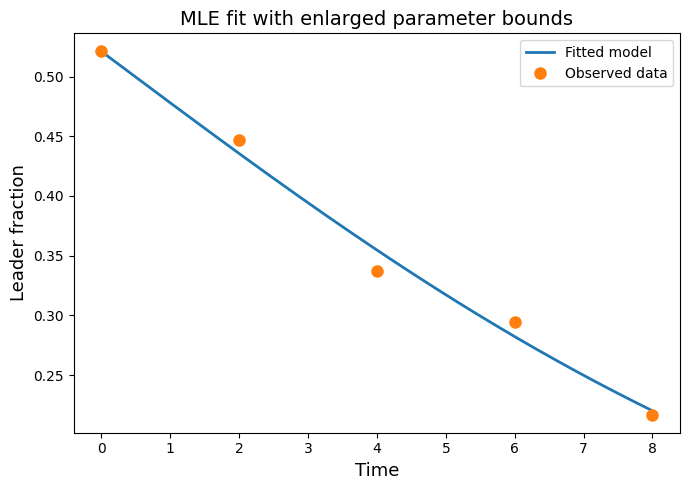

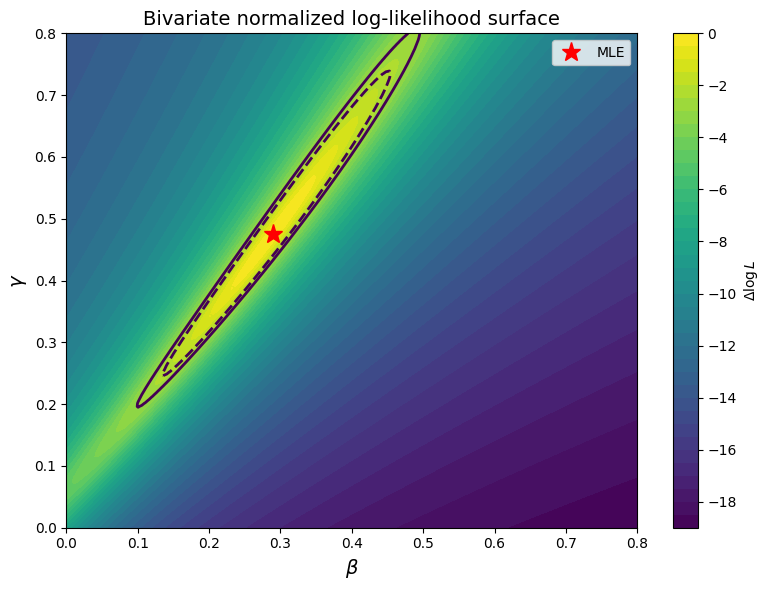

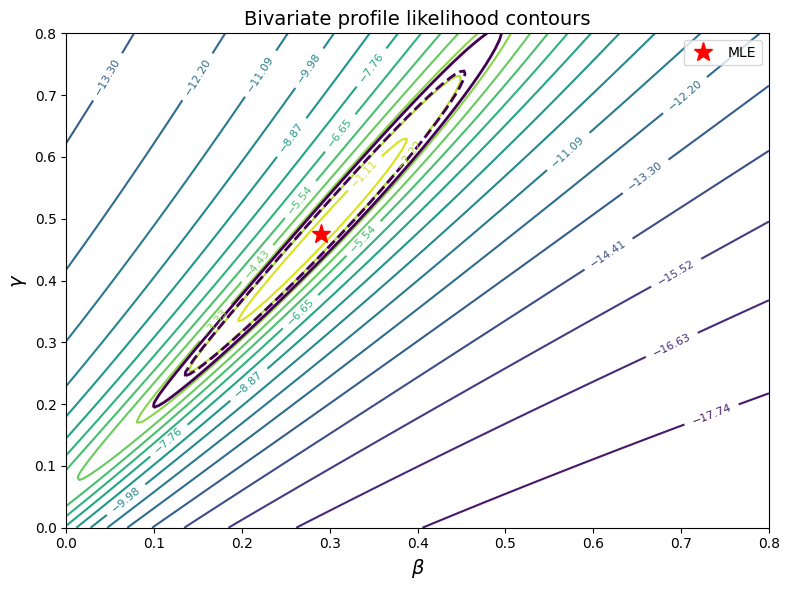


===== Best grid point =====
beta_grid_best  = 0.29182390
gamma_grid_best = 0.47798742
logLik_grid     = 15.55324189
Delta from optimizer MLE = -3.19124927e-03


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize, differential_evolution
from scipy.stats import chi2

# ============================================================
# 1. Observed data
# ============================================================
t_obs = np.array([0, 2, 4, 6, 8], dtype=float)
y_obs = np.array([0.521, 0.447058824, 0.3375, 0.294117647, 0.216923077], dtype=float)

y0 = float(y_obs[0])
n_obs = len(y_obs)

# ============================================================
# 2. Fixed parameters
# ============================================================
alpha = 0.2903
delta = 0.4489

# ============================================================
# 3. ODE model
# ============================================================
def ode_rhs(t, y, x):
    beta, gamma = x
    yl = y[0]

    F_l = alpha * yl + beta * (1.0 - yl)
    F_f = gamma * yl + delta * (1.0 - yl)

    dydt = (F_l - F_f) * yl * (1.0 - yl)
    return [dydt]

def solve_model(t_eval, x, y0):
    try:
        sol = solve_ivp(
            fun=lambda t, y: ode_rhs(t, y, x),
            t_span=(float(t_eval[0]), float(t_eval[-1])),
            y0=[y0],
            t_eval=t_eval,
            method="LSODA",
            rtol=1e-8,
            atol=1e-10,
        )
    except Exception:
        return np.full_like(t_eval, np.nan, dtype=float)

    if (not sol.success) or np.any(~np.isfinite(sol.y)):
        return np.full_like(t_eval, np.nan, dtype=float)

    return sol.y[0]

# ============================================================
# 4. Profiled Gaussian log-likelihood
# ============================================================
def loglikelihood_profiled_sigma(x, t_obs, y_obs, y0):
    if np.any(~np.isfinite(x)):
        return -np.inf

    y_pred = solve_model(t_obs, x, y0)
    if np.any(~np.isfinite(y_pred)):
        return -np.inf

    resid = y_obs - y_pred
    sse = np.sum(resid**2)
    sigma2_hat = sse / len(y_obs)

    if sigma2_hat <= 0 or not np.isfinite(sigma2_hat):
        return -np.inf

    n = len(y_obs)
    ll = -0.5 * n * (1.0 + np.log(2.0 * np.pi) + np.log(sigma2_hat))
    return ll

def neg_loglikelihood_profiled_sigma(x, t_obs, y_obs, y0):
    ll = loglikelihood_profiled_sigma(x, t_obs, y_obs, y0)
    if not np.isfinite(ll):
        return 1e100
    return -ll

# ============================================================
# 5. Larger parameter bounds
# ============================================================
bounds = [
    (0, 0.8),   # beta
    (0.0, 0.8),    # gamma
]

# ============================================================
# 6. MLE on the larger bounds
# ============================================================
print("Running global optimization...")
res_global = differential_evolution(
    func=lambda x: neg_loglikelihood_profiled_sigma(x, t_obs, y_obs, y0),
    bounds=bounds,
    maxiter=120,
    popsize=25,
    polish=False,
    seed=42,
    updating="deferred",
)

print("Refining with local optimization...")
res_local = minimize(
    fun=lambda x: neg_loglikelihood_profiled_sigma(x, t_obs, y_obs, y0),
    x0=res_global.x,
    method="L-BFGS-B",
    bounds=bounds,
    options={"maxiter": 3000, "ftol": 1e-14},
)

theta_mle = res_local.x
ll_mle = loglikelihood_profiled_sigma(theta_mle, t_obs, y_obs, y0)

print("\n===== MLE on larger bounds =====")
print(f"beta_hat  = {theta_mle[0]:.8f}")
print(f"gamma_hat = {theta_mle[1]:.8f}")
print(f"logLik    = {ll_mle:.8f}")

# ============================================================
# 7. Bivariate likelihood surface on a grid
# ============================================================
n_beta = 160
n_gamma = 160

beta_grid = np.linspace(bounds[0][0], bounds[0][1], n_beta)
gamma_grid = np.linspace(bounds[1][0], bounds[1][1], n_gamma)

LL = np.full((n_gamma, n_beta), np.nan)

print("\nEvaluating bivariate likelihood surface...")
for i, gamma in enumerate(gamma_grid):
    for j, beta in enumerate(beta_grid):
        x = np.array([beta, gamma], dtype=float)
        LL[i, j] = loglikelihood_profiled_sigma(x, t_obs, y_obs, y0)

LL_norm = LL - ll_mle   # normalized log-likelihood

# ============================================================
# 8. Approximate 95% joint confidence region threshold
#    For 2 parameters:
#    Delta logLik = -0.5 * chi2_{0.95,2}
# ============================================================
joint_cutoff_95 = -0.5 * chi2.ppf(0.95, df=2)
joint_cutoff_90 = -0.5 * chi2.ppf(0.90, df=2)

print(f"95% joint cutoff (2 params) = {joint_cutoff_95:.6f}")
print(f"90% joint cutoff (2 params) = {joint_cutoff_90:.6f}")

# ============================================================
# 9. Plot fitted trajectory
# ============================================================
t_fine = np.linspace(t_obs[0], t_obs[-1], 400)
y_fit = solve_model(t_fine, theta_mle, y0)

plt.figure(figsize=(7, 5))
plt.plot(t_fine, y_fit, lw=2, label="Fitted model")
plt.plot(t_obs, y_obs, 'o', ms=8, label="Observed data")
plt.xlabel("Time", fontsize=13)
plt.ylabel("Leader fraction", fontsize=13)
plt.title("MLE fit with enlarged parameter bounds", fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 10. Filled contour plot of bivariate profile likelihood
# ============================================================
BETA, GAMMA = np.meshgrid(beta_grid, gamma_grid)

plt.figure(figsize=(8, 6))
cf = plt.contourf(BETA, GAMMA, LL_norm, levels=40)
plt.colorbar(cf, label=r'$\Delta \log L$')

# joint confidence contours
c95 = plt.contour(
    BETA, GAMMA, LL_norm,
    levels=[joint_cutoff_95],
    linewidths=2
)
c90 = plt.contour(
    BETA, GAMMA, LL_norm,
    levels=[joint_cutoff_90],
    linewidths=2,
    linestyles='--'
)

plt.plot(theta_mle[0], theta_mle[1], 'r*', ms=14, label='MLE')
plt.xlabel(r'$\beta$', fontsize=14)
plt.ylabel(r'$\gamma$', fontsize=14)
plt.title('Bivariate normalized log-likelihood surface', fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 11. Line contour plot only
# ============================================================
plt.figure(figsize=(8, 6))
levels = np.linspace(np.nanmin(LL_norm), 0, 18)
cs = plt.contour(BETA, GAMMA, LL_norm, levels=levels)
plt.clabel(cs, inline=True, fontsize=8)

plt.contour(BETA, GAMMA, LL_norm, levels=[joint_cutoff_95], linewidths=2)
plt.contour(BETA, GAMMA, LL_norm, levels=[joint_cutoff_90], linewidths=2, linestyles='--')

plt.plot(theta_mle[0], theta_mle[1], 'r*', ms=14, label='MLE')
plt.xlabel(r'$\beta$', fontsize=14)
plt.ylabel(r'$\gamma$', fontsize=14)
plt.title('Bivariate profile likelihood contours', fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 12. Optional: print best point found on the grid
# ============================================================
imax, jmax = np.unravel_index(np.nanargmax(LL), LL.shape)
beta_grid_best = beta_grid[jmax]
gamma_grid_best = gamma_grid[imax]
ll_grid_best = LL[imax, jmax]

print("\n===== Best grid point =====")
print(f"beta_grid_best  = {beta_grid_best:.8f}")
print(f"gamma_grid_best = {gamma_grid_best:.8f}")
print(f"logLik_grid     = {ll_grid_best:.8f}")
print(f"Delta from optimizer MLE = {ll_grid_best - ll_mle:.8e}")

Running global optimization...
Refining with local optimization...

===== MLE on larger bounds =====
beta_hat  = 0.17669681
gamma_hat = 0.26191464
logLik    = 19.33103872

Evaluating bivariate likelihood surface...
95% joint cutoff (2 params) = -2.995732
90% joint cutoff (2 params) = -2.302585


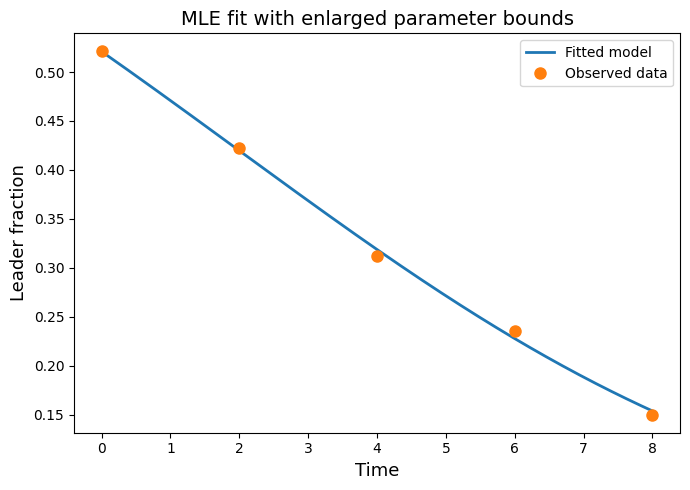

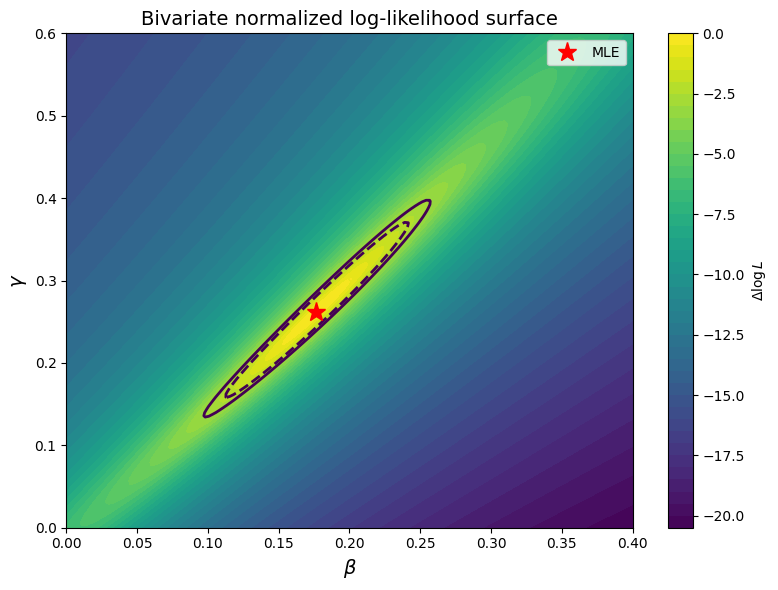

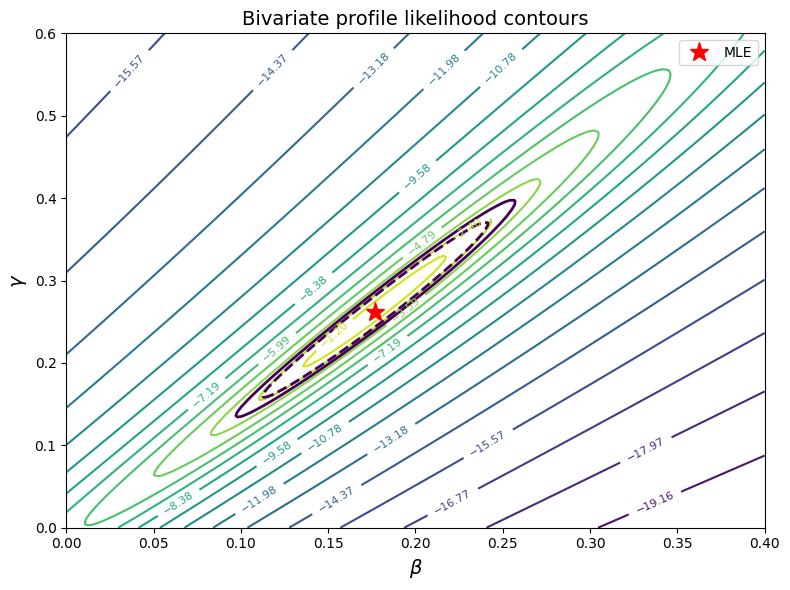


===== Best grid point =====
beta_grid_best  = 0.17610063
gamma_grid_best = 0.26037736
logLik_grid     = 19.32726338
Delta from optimizer MLE = -3.77533934e-03


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize, differential_evolution
from scipy.stats import chi2

# ============================================================
# 1. Observed data
# ============================================================
t_obs = np.array([0, 2, 4, 6, 8], dtype=float)
y_obs = np.array([0.521, 0.421875, 0.312, 0.235714286, 0.15], dtype=float)

y0 = float(y_obs[0])
n_obs = len(y_obs)

# ============================================================
# 2. Fixed parameters
# ============================================================
alpha = 0.1292
delta = 0.4443

# ============================================================
# 3. ODE model
# ============================================================
def ode_rhs(t, y, x):
    beta, gamma = x
    yl = y[0]

    F_l = alpha * yl + beta * (1.0 - yl)
    F_f = gamma * yl + delta * (1.0 - yl)

    dydt = (F_l - F_f) * yl * (1.0 - yl)
    return [dydt]

def solve_model(t_eval, x, y0):
    try:
        sol = solve_ivp(
            fun=lambda t, y: ode_rhs(t, y, x),
            t_span=(float(t_eval[0]), float(t_eval[-1])),
            y0=[y0],
            t_eval=t_eval,
            method="LSODA",
            rtol=1e-8,
            atol=1e-10,
        )
    except Exception:
        return np.full_like(t_eval, np.nan, dtype=float)

    if (not sol.success) or np.any(~np.isfinite(sol.y)):
        return np.full_like(t_eval, np.nan, dtype=float)

    return sol.y[0]

# ============================================================
# 4. Profiled Gaussian log-likelihood
# ============================================================
def loglikelihood_profiled_sigma(x, t_obs, y_obs, y0):
    if np.any(~np.isfinite(x)):
        return -np.inf

    y_pred = solve_model(t_obs, x, y0)
    if np.any(~np.isfinite(y_pred)):
        return -np.inf

    resid = y_obs - y_pred
    sse = np.sum(resid**2)
    sigma2_hat = sse / len(y_obs)

    if sigma2_hat <= 0 or not np.isfinite(sigma2_hat):
        return -np.inf

    n = len(y_obs)
    ll = -0.5 * n * (1.0 + np.log(2.0 * np.pi) + np.log(sigma2_hat))
    return ll

def neg_loglikelihood_profiled_sigma(x, t_obs, y_obs, y0):
    ll = loglikelihood_profiled_sigma(x, t_obs, y_obs, y0)
    if not np.isfinite(ll):
        return 1e100
    return -ll

# ============================================================
# 5. Larger parameter bounds
# ============================================================
bounds = [
    (0, 0.4),   # beta
    (0.0, 0.6),    # gamma
]

# ============================================================
# 6. MLE on the larger bounds
# ============================================================
print("Running global optimization...")
res_global = differential_evolution(
    func=lambda x: neg_loglikelihood_profiled_sigma(x, t_obs, y_obs, y0),
    bounds=bounds,
    maxiter=120,
    popsize=25,
    polish=False,
    seed=42,
    updating="deferred",
)

print("Refining with local optimization...")
res_local = minimize(
    fun=lambda x: neg_loglikelihood_profiled_sigma(x, t_obs, y_obs, y0),
    x0=res_global.x,
    method="L-BFGS-B",
    bounds=bounds,
    options={"maxiter": 3000, "ftol": 1e-14},
)

theta_mle = res_local.x
ll_mle = loglikelihood_profiled_sigma(theta_mle, t_obs, y_obs, y0)

print("\n===== MLE on larger bounds =====")
print(f"beta_hat  = {theta_mle[0]:.8f}")
print(f"gamma_hat = {theta_mle[1]:.8f}")
print(f"logLik    = {ll_mle:.8f}")

# ============================================================
# 7. Bivariate likelihood surface on a grid
# ============================================================
n_beta = 160
n_gamma = 160

beta_grid = np.linspace(bounds[0][0], bounds[0][1], n_beta)
gamma_grid = np.linspace(bounds[1][0], bounds[1][1], n_gamma)

LL = np.full((n_gamma, n_beta), np.nan)

print("\nEvaluating bivariate likelihood surface...")
for i, gamma in enumerate(gamma_grid):
    for j, beta in enumerate(beta_grid):
        x = np.array([beta, gamma], dtype=float)
        LL[i, j] = loglikelihood_profiled_sigma(x, t_obs, y_obs, y0)

LL_norm = LL - ll_mle   # normalized log-likelihood

# ============================================================
# 8. Approximate 95% joint confidence region threshold
#    For 2 parameters:
#    Delta logLik = -0.5 * chi2_{0.95,2}
# ============================================================
joint_cutoff_95 = -0.5 * chi2.ppf(0.95, df=2)
joint_cutoff_90 = -0.5 * chi2.ppf(0.90, df=2)

print(f"95% joint cutoff (2 params) = {joint_cutoff_95:.6f}")
print(f"90% joint cutoff (2 params) = {joint_cutoff_90:.6f}")

# ============================================================
# 9. Plot fitted trajectory
# ============================================================
t_fine = np.linspace(t_obs[0], t_obs[-1], 400)
y_fit = solve_model(t_fine, theta_mle, y0)

plt.figure(figsize=(7, 5))
plt.plot(t_fine, y_fit, lw=2, label="Fitted model")
plt.plot(t_obs, y_obs, 'o', ms=8, label="Observed data")
plt.xlabel("Time", fontsize=13)
plt.ylabel("Leader fraction", fontsize=13)
plt.title("MLE fit with enlarged parameter bounds", fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 10. Filled contour plot of bivariate profile likelihood
# ============================================================
BETA, GAMMA = np.meshgrid(beta_grid, gamma_grid)

plt.figure(figsize=(8, 6))
cf = plt.contourf(BETA, GAMMA, LL_norm, levels=40)
plt.colorbar(cf, label=r'$\Delta \log L$')

# joint confidence contours
c95 = plt.contour(
    BETA, GAMMA, LL_norm,
    levels=[joint_cutoff_95],
    linewidths=2
)
c90 = plt.contour(
    BETA, GAMMA, LL_norm,
    levels=[joint_cutoff_90],
    linewidths=2,
    linestyles='--'
)

plt.plot(theta_mle[0], theta_mle[1], 'r*', ms=14, label='MLE')
plt.xlabel(r'$\beta$', fontsize=14)
plt.ylabel(r'$\gamma$', fontsize=14)
plt.title('Bivariate normalized log-likelihood surface', fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 11. Line contour plot only
# ============================================================
plt.figure(figsize=(8, 6))
levels = np.linspace(np.nanmin(LL_norm), 0, 18)
cs = plt.contour(BETA, GAMMA, LL_norm, levels=levels)
plt.clabel(cs, inline=True, fontsize=8)

plt.contour(BETA, GAMMA, LL_norm, levels=[joint_cutoff_95], linewidths=2)
plt.contour(BETA, GAMMA, LL_norm, levels=[joint_cutoff_90], linewidths=2, linestyles='--')

plt.plot(theta_mle[0], theta_mle[1], 'r*', ms=14, label='MLE')
plt.xlabel(r'$\beta$', fontsize=14)
plt.ylabel(r'$\gamma$', fontsize=14)
plt.title('Bivariate profile likelihood contours', fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 12. Optional: print best point found on the grid
# ============================================================
imax, jmax = np.unravel_index(np.nanargmax(LL), LL.shape)
beta_grid_best = beta_grid[jmax]
gamma_grid_best = gamma_grid[imax]
ll_grid_best = LL[imax, jmax]

print("\n===== Best grid point =====")
print(f"beta_grid_best  = {beta_grid_best:.8f}")
print(f"gamma_grid_best = {gamma_grid_best:.8f}")
print(f"logLik_grid     = {ll_grid_best:.8f}")
print(f"Delta from optimizer MLE = {ll_grid_best - ll_mle:.8e}")